# Functional distortion tutorial

Compare a Y graph with an upside-down Y. They have the same unlabelled shape, but their forks occur at different heights. We’ll build maps from one fitted interleaving, vary the construction rules, and compare the resulting functional distortion costs.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from cereeberus import Interleave, MapperGraph
from core.distortion import functional_distortion
from core.fd_map_build import maps_from_interleave
from visualize.fd_metromaps import draw_fd_maps


## 1. Build the graphs and fit the interleaving

Vertices have integer heights. Each edge connects adjacent levels. The interleaving is fitted once so the comparisons below use the same assignment.

In [2]:
def make_graph(nodes, edges):
    M = MapperGraph()
    for name, h in nodes:
        M.add_node(name, h)
    for u, v in edges:
        M.add_edge(u, v)
    return M


def _y_data():
    YF_n = [("f0", 0), ("f1", 1), ("f2", 2), ("j", 3), ("L4", 4), ("L5", 5), ("R4", 4)]
    YF_e = [("f0", "f1"),("f1", "f2"),("f2", "j"),("j", "L4"),("L4", "L5"),("j", "R4")]
    YG_n = [("g5", 5), ("g4", 4), ("g3", 3), ("q", 2), ("b1", 1), ("b0", 0), ("c1", 1)]
    YG_e = [("g5", "g4"),("g4", "g3"),("g3", "q"),("q", "b1"),("b1", "b0"),("q", "c1")]
    
    return (YF_n, YF_e, YG_n, YG_e)

F_nodes, F_edges, G_nodes, G_edges = _y_data()
mapper_F = make_graph(F_nodes, F_edges)
mapper_G = make_graph(G_nodes, G_edges)


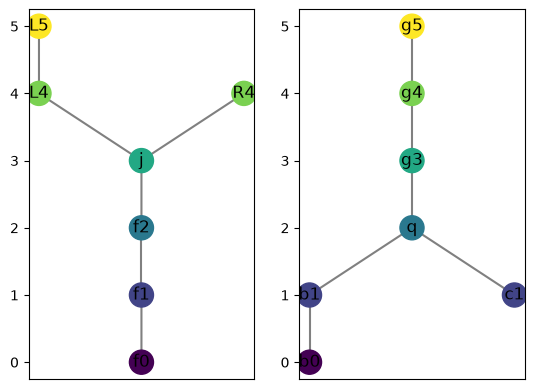

In [3]:
# draw the mappers

fig, (ax_F, ax_G) = plt.subplots(1, 2)
mapper_F.draw(ax=ax_F)
mapper_G.draw(ax=ax_G)
plt.show()


In [4]:
# fit the interleaving
interleaving = Interleave(mapper_F, mapper_G)
print("Interleaving parameter:", interleaving.fit())


Interleaving parameter: 1


## 2. Build the maps

Pass the fitted interleaving to `maps_from_interleave`. Use the returned graphs and maps together in the next cells.

Change `map_seed` to try different tie-breaks. Reuse the same seed, fitted interleaving, and construction options to reproduce the same maps. After changing the seed, rerun this cell and the cells below it.

In [5]:
map_seed = 100
fd_maps = maps_from_interleave(interleaving, seed=map_seed)
F, G = fd_maps["F"], fd_maps["G"]
Phi, Psi = fd_maps["Phi"], fd_maps["Psi"]


### Compare seeds on the same fitted interleaving

Different seeds can give the same maps when the available choices are limited. Even when a map changes, its distortion score can stay the same. Compare the vertex images and edge pieces directly.

In [6]:
comparison_seed = map_seed + 1
other_maps = maps_from_interleave(interleaving, seed=comparison_seed)

print(f"Seed {map_seed} → seed {comparison_seed}")
for direction in ("Phi", "Psi"):
    first, second = fd_maps[direction], other_maps[direction]
    print(f"{direction}:")
    for vertex, image in first["vertex_image"].items():
        other_image = second["vertex_image"][vertex]
        if image != other_image:
            print(f"  {vertex}: {image} → {other_image}")
    changed_edges = [
        edge for edge, pieces in first["segments"].items()
        if pieces != second["segments"][edge]
    ]
    print("  Changed edge pieces on:", changed_edges)


Seed 100 → seed 101
Phi:
  Changed edge pieces on: []
Psi:
  Changed edge pieces on: []


### Draw the maps

Each row shows the source on the left and the target on the right.

Use `Phi.draw()` or `Psi.draw()` to show just one direction.

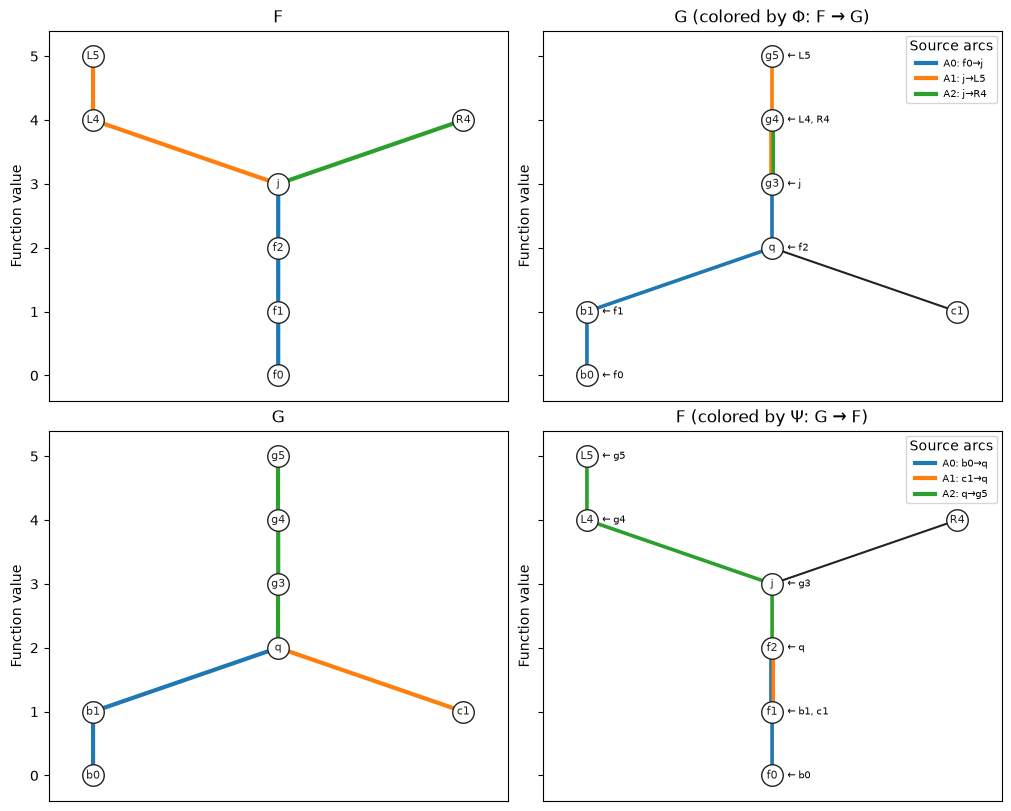

In [7]:
draw_fd_maps(Phi, Psi, names=("F", "G"), figsize=(10, 8))
plt.show()


In [8]:
distortion_result = functional_distortion(F, G, Phi, Psi, decimals=3)
print(f"maxₓ |f(x) − g(Φ(x))| = {distortion_result['height_Phi_units']}")
print(f"maxᵧ |g(y) − f(Ψ(y))| = {distortion_result['height_Psi_units']}")
print(f"D = {distortion_result['D_units']}")
print(f"Functional distortion = {distortion_result['FD_units']}")


maxₓ |f(x) − g(Φ(x))| = 0.0
maxᵧ |g(y) − f(Ψ(y))| = 0.0
D = 0.5
Functional distortion = 0.5


### Distortion witnesses

Each height witness is a (source point, image point) pair. The witness for D gives the two matched pairs and their distances.

In [9]:
print("Φ height witness:", distortion_result["witness_height_Phi"])
print("Ψ height witness:", distortion_result["witness_height_Psi"])

witness = distortion_result["witness_D"]
print("D witness:", witness["pair"])
print("d_f:", witness["d_f"])
print("d_g:", witness["d_g"])
print("D:", distortion_result["D_units"])


Φ height witness: (('v', 'f0'), ('v', 'b0'))
Ψ height witness: (('v', 'g5'), ('v', 'L5'))
D witness: ((('v', 'L4'), ('v', 'g4')), (('v', 'R4'), ('v', 'g4')))
d_f: 1
d_g: 0
D: 0.5


## 3. Compare construction choices

- `points` controls the selection of vertex images and handoff points within the allowed sets. `random` samples among the nearest-height candidates. `close` (the default) also scores route spans, and `joint` scores the two directions together using vertex round trips.
- `paths` chooses the route inside each allowed set. `fewest_edges` favors short walks, while `min_span` (the default) uses one shared height window for the entire route through the handoff. It minimizes the width first, then the total edge count.
- `seed` controls random choices.

Compare the first two rows for the effect of the path rule. Compare the baseline, random, and round-trip rows for the effect of point selection. All scores use the same evaluator.

In [10]:
choices = [
    ("Baseline", "close", "min_span"),
    ("Change path rule", "close", "fewest_edges"),
    ("Random point selection", "random", "min_span"),
    ("Score round trips", "joint", "min_span"),
]
runs = {}
rows = []
for label, points, paths in choices:
    maps = fd_maps if label == "Baseline" else maps_from_interleave(
        interleaving, seed=map_seed, points=points, paths=paths
    )
    result = functional_distortion(*(maps[key] for key in ("F", "G", "Phi", "Psi")), decimals=3)
    runs[label] = maps, result
    rows.append({"Setting": label, "points": points, "paths": paths,
                 "Height error Φ": result["height_Phi_units"],
                 "Height error Ψ": result["height_Psi_units"],
                 "D": result["D_units"], "FD": result["FD_units"]})
table = pd.DataFrame(rows).set_index("Setting")
display(table)
best_label = min(runs, key=lambda label: runs[label][1]["FD_units"])
print(f"Lowest FD among these runs: {runs[best_label][1]['FD_units']}")


,points,paths,Height error Φ,Height error Ψ,D,FD
Setting,,,,,,
Baseline,close,min_span,0.0,0.0,0.5,0.5
Change path rule,close,fewest_edges,0.0,0.0,0.5,0.5
Random point selection,random,min_span,1.0,0.0,0.5,1.0
Score round trips,joint,min_span,0.0,0.0,0.5,0.5


Lowest FD among these runs: 0.5


## 4. Show Fréchet parameters

Pass `show_frechet_param=True` to label matching source and target breakpoints. Leader lines on the source point to the exact locations, including points close to a vertex.

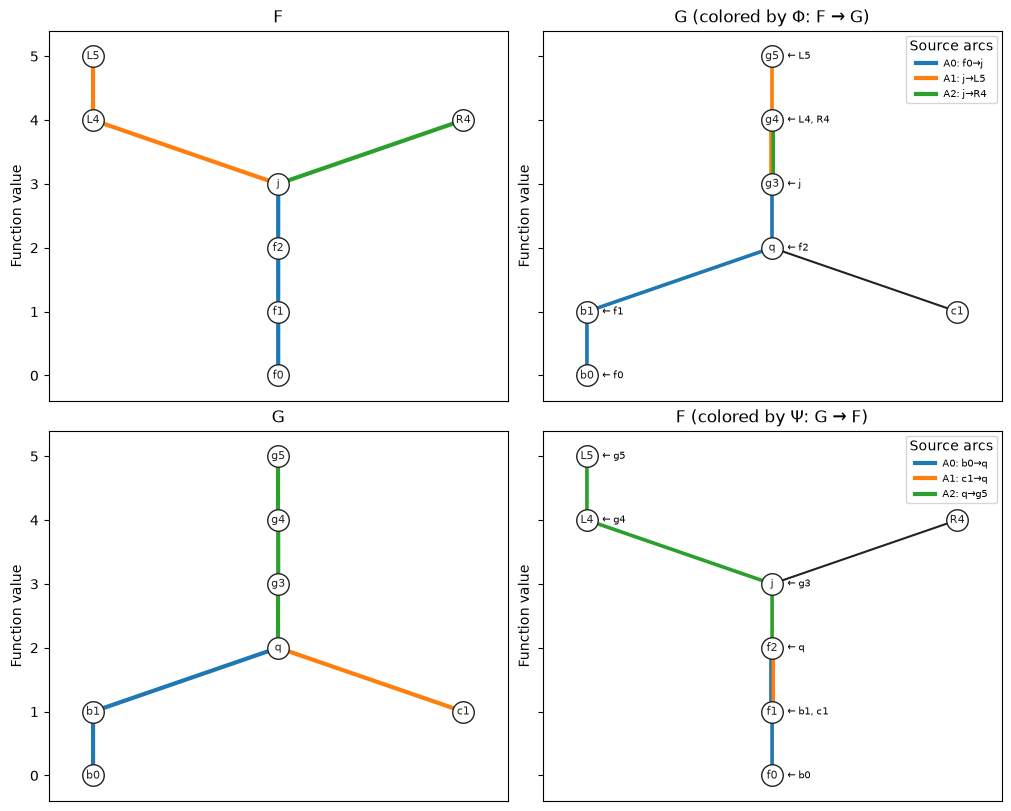

In [11]:
draw_fd_maps(Phi, Psi, figsize=(10, 8), show_frechet_param=True)
plt.show()
